## **Global Retail & E-Commerce Product Prices.**



#### **Profile Dataset**
*   Nama dan gambaran dataset:
berisi informasi tentang harga produk retail dari berbagai lokasi, termasuk informasi produk dan tempat harga tersebut dicatat.
*   Sumber data: Open Food Facts — Open Prices, yaitu engumpulan harga yang melibatkan kontribusi publik, seperti harga pada struk belanja dan label harga di toko.
* Tujuan penggunaan: Menganalisis perbedaan harga antarwilayah, Mempelajari perubahan harga atau inflasi, Membantu analisis strategi harga supermarket, Menganalisis harga berdasarkan kategori dan merek.
* Struktur data: mencantumkan 12 kolom, misalnya nama produk, merek, kategori, harga, mata uang, toko, negara, dan tanggal pencatatan.
* diketahui ada 20 mata uang, tapi prioritas analisis yaitu: **EUR, USD, NOK, BAM, dan SEK.**


#### **Tujuan**
**Mengidentifikasi pola catatan harga dan karakteristik produk berdasarkan kelompok mata uang untuk menentukan aspek yang perlu diperhatikan lebih lanjut dalam pengelolaan produk dan harga.**,

hal yang ingin diketahui:
- Berapa banyak catatan harga pada setiap mata uang?
- Bagaimana karakteristik harga yang tercatat, mulai dari nilai tengah, rata-rata, hingga penyebaran harganya?
- Kategori produk apa yang paling banyak muncul pada masing-masing mata uang?
- Produk apa saja yang memiliki jumlah catatan harga terbanyak?
- Apakah terdapat perbedaan pola kategori produk antara EUR dan USD?
- Bagaimana kualitas data produk dan informasi diskon yang tersedia?

In [12]:

import pandas as pd
from google.colab import files

uploaded = files.upload()


Saving global_retail_prices_dataset.csv to global_retail_prices_dataset (2).csv


In [13]:
nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())


Ukuran dataset: (2000, 12)

Nama kolom:
['price_record_id', 'product_code', 'product_name', 'brand', 'category', 'price', 'currency', 'price_is_discounted', 'store_name', 'city', 'country_code', 'date_recorded']

5 data pertama:


,price_record_id,product_code,product_name,brand,category,price,currency,price_is_discounted,store_name,city,country_code,date_recorded
0,339639,NaN,APFEL ROT LOSE,NaN,en:apples,2.08,EUR,False,jbieber,Hofer,NaN,2026-10-03
1,339638,4061461467661,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03
2,339637,NaN,Toskanabrot 360g,NaN,en:white-breads,1.80,EUR,False,jbieber,Hofer,NaN,2026-10-03
3,339636,4061464512245,Waffelhörn. Erdb.,NaN,NaN,0.49,EUR,False,jbieber,Hofer,NaN,2026-10-03
4,339635,4061458026819,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03


In [14]:

# 1. Periksa nilai kosong
print("Nilai kosong pada kolom utama:")
display(df[["price", "currency"]].isnull().sum())

# 2. Periksa harga nol atau negatif
print("\nJumlah harga nol atau negatif:")
print((df["price"] <= 0).sum())

# 3. Periksa mata uang
print("\nJumlah catatan per mata uang:")
display(df["currency"].value_counts(dropna=False))


Nilai kosong pada kolom utama:


,0
price,0
currency,0



Jumlah harga nol atau negatif:
0

Jumlah catatan per mata uang:


,count
currency,
EUR,994
USD,407
NOK,190
BAM,122
SEK,118
CZK,73
KZT,35
PLN,21
SGD,16


#### **menghitung statistik deskriptif**

In [15]:

statistik = df.groupby("currency")["price"].describe()

display(statistik.round(2))


,count,mean,std,min,25%,50%,75%,max
currency,,,,,,,,
BAM,122.0,4.35,4.57,0.29,1.49,2.47,5.86,27.99
BIF,2.0,2000.00,0.00,2000.00,2000.00,2000.00,2000.00,2000.00
BRL,1.0,6.99,NaN,6.99,6.99,6.99,6.99,6.99
CLP,1.0,1390.00,NaN,1390.00,1390.00,1390.00,1390.00,1390.00
CZK,73.0,73.13,87.93,9.90,23.90,35.90,59.90,319.00
EUR,994.0,3.20,2.85,0.23,1.79,2.50,3.69,29.01
GBP,2.0,1.90,0.15,1.79,1.84,1.90,1.95,2.00
HUF,1.0,1299.00,NaN,1299.00,1299.00,1299.00,1299.00,1299.00
ILS,5.0,6.34,2.04,5.00,5.00,5.90,5.90,9.90


### **melihat distribusi harga produk EUR**

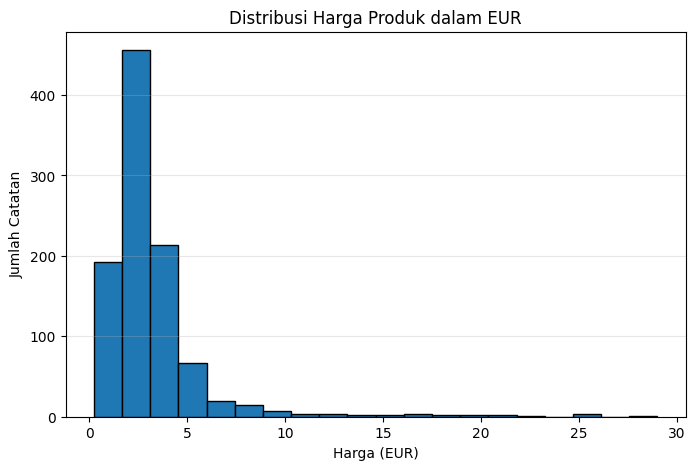

In [16]:

import matplotlib.pyplot as plt

# Ambil catatan harga dengan mata uang EUR
harga_eur = df.loc[df["currency"] == "EUR", "price"]

# Buat histogram
plt.figure(figsize=(8, 5))
plt.hist(harga_eur, bins=20, edgecolor="black")

plt.title("Distribusi Harga Produk dalam EUR")
plt.xlabel("Harga (EUR)")
plt.ylabel("Jumlah Catatan")
plt.grid(axis="y", alpha=0.3)

plt.show()


Distribusi harga produk dalam mata uang EUR menunjukkan bahwa sebagian besar catatan harga terkonsentrasi pada rentang harga rendah, terutama sekitar €2–€3. Distribusinya menceng ke kanan karena terdapat sejumlah kecil catatan dengan harga jauh lebih tinggi. Median harga sebesar €2,50, sedangkan harga tertinggi mencapai €29,01.

##### **mengetahui dominasi kelompok tertentu**
apakah penyebaran di daerah 2-3 euro didominasi oleh produk atau toko?

In [17]:
# Ambil catatan EUR dengan harga €1 sampai €4
data_eur_rendah = df[
    (df["currency"] == "EUR") &
    (df["price"] >= 1) &
    (df["price"] <= 4)
]

# Tampilkan informasi yang diperlukan
display(
    data_eur_rendah[
        ["product_name", "price", "store_name", "category"]
    ].head(15)
)

,product_name,price,store_name,category
0,APFEL ROT LOSE,2.08,jbieber,en:apples
1,Orient. Salat 200g,1.29,jbieber,NaN
2,Toskanabrot 360g,1.80,jbieber,en:white-breads
4,Orient. Salat 200g,1.29,jbieber,NaN
6,Milchbrötchen,1.85,jbieber,NaN
7,Hummus 200 g,1.69,jbieber,NaN
9,Noisette 100g,1.25,jbieber,NaN
10,Bananen lose,1.59,jbieber,en:bananas
13,Gourmet Chips 125g,1.79,jbieber,NaN
14,Apfelmus 710g,1.59,jbieber,NaN


In [18]:
# Hitung jumlah catatan harga €1–€4 berdasarkan toko
jumlah_per_toko = (
    data_eur_rendah["store_name"]
    .value_counts()
    .reset_index()
)

jumlah_per_toko.columns = ["Nama Toko", "Jumlah Catatan"]

display(jumlah_per_toko.head(10))

,Nama Toko,Jumlah Catatan
0,poslovitch,424
1,sebleouf,142
2,tartelette299,27
3,stephane,26
4,jangop,18
5,monsieurtanuki,17
6,k127,12
7,jbieber,12
8,piterpan2,11
9,guillaume029371,10


In [19]:
# Hitung seluruh catatan EUR berdasarkan toko
jumlah_toko_eur = (
    df[df["currency"] == "EUR"]["store_name"]
    .value_counts()
    .reset_index()
)

jumlah_toko_eur.columns = ["Nama Toko", "Total Catatan EUR"]

display(jumlah_toko_eur.head(10))

,Nama Toko,Total Catatan EUR
0,poslovitch,502
1,sebleouf,193
2,tartelette299,52
3,stephane,36
4,jangop,22
5,jbieber,19
6,monsieurtanuki,18
7,k127,18
8,guillaume029371,16
9,lpdj,14


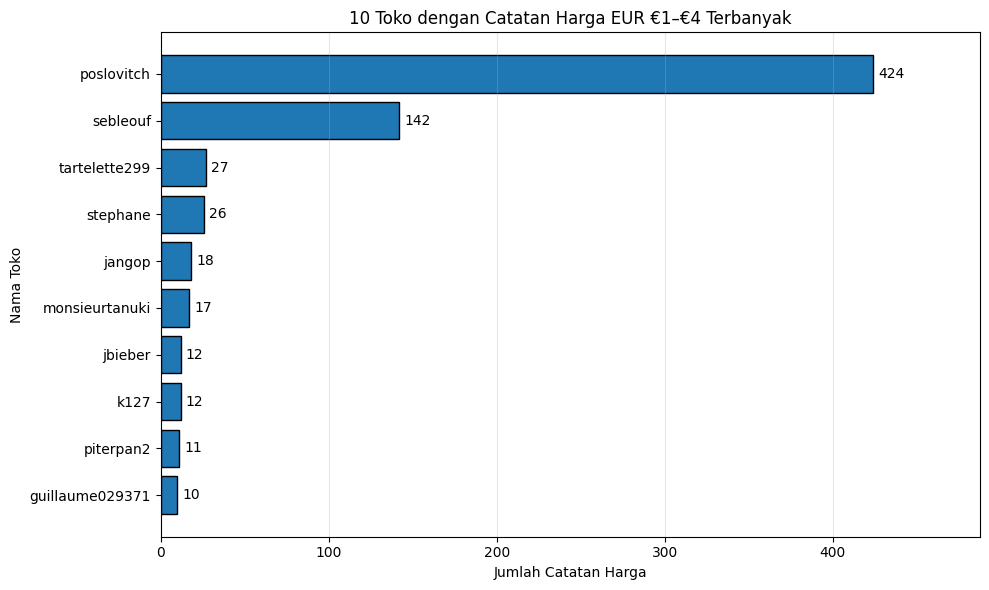

In [20]:
import matplotlib.pyplot as plt

# Filter catatan harga EUR pada rentang €1–€4
data_eur_rendah = df[
    (df["currency"] == "EUR") &
    (df["price"] >= 1) &
    (df["price"] <= 4)
]

# Hitung jumlah catatan berdasarkan toko
jumlah_toko = data_eur_rendah["store_name"].value_counts()

# Ambil 10 toko dengan catatan terbanyak
top_10 = jumlah_toko.head(10).sort_values()

# Buat visualisasi
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10.index, top_10.values, edgecolor="black")

plt.title("10 Toko dengan Catatan Harga EUR €1–€4 Terbanyak")
plt.xlabel("Jumlah Catatan Harga")
plt.ylabel("Nama Toko")

# Tampilkan angka pada setiap batang
for bar in bars:
    plt.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

plt.xlim(0, top_10.max() * 1.15)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Catatan harga produk dalam mata uang EUR pada rentang €1–€4 didominasi oleh toko poslovitch, yang menyumbang sekitar 68,2% dari seluruh catatan dalam rentang tersebut. Selain itu, sekitar 84,5% catatan EUR dari toko ini berada pada rentang harga €1–€4.

##### **Mengetahui dominasi jenis produk pada toko poslovitch**

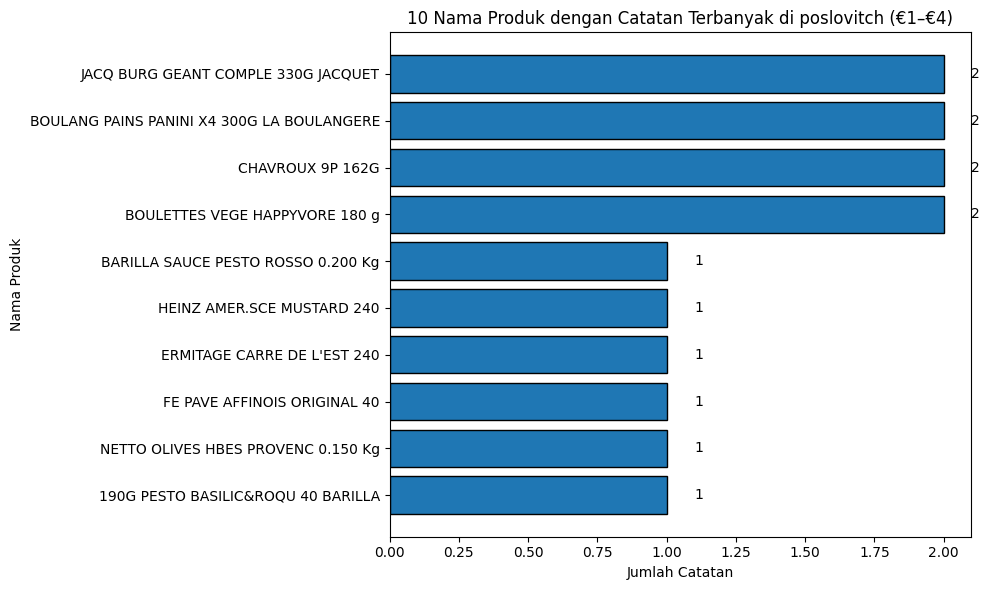

In [21]:
# Filter data EUR €1–€4 dari toko poslovitch
data_poslovitch = df[
    (df["currency"] == "EUR") &
    (df["price"] >= 1) &
    (df["price"] <= 4) &
    (df["store_name"] == "poslovitch")
]

# Hitung jumlah catatan untuk setiap nama produk
produk_teratas = (
    data_poslovitch["product_name"]
    .value_counts()
    .head(10)
    .sort_values()
)

# Visualisasikan 10 produk dengan catatan terbanyak
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
bars = plt.barh(
    produk_teratas.index,
    produk_teratas.values,
    edgecolor="black"
)

plt.title("10 Nama Produk dengan Catatan Terbanyak di poslovitch (€1–€4)")
plt.xlabel("Jumlah Catatan")
plt.ylabel("Nama Produk")

for bar in bars:
    plt.text(
        bar.get_width() + 0.1,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

plt.tight_layout()
plt.show()

In [22]:
# Hitung total catatan dan nama produk unik
total_catatan = len(data_poslovitch)
produk_unik = data_poslovitch["product_name"].nunique()
produk_kosong = data_poslovitch["product_name"].isna().sum()

print("Total catatan harga €1–€4:", total_catatan)
print("Jumlah nama produk unik:", produk_unik)
print("Catatan tanpa nama produk:", produk_kosong)

Total catatan harga €1–€4: 424
Jumlah nama produk unik: 419
Catatan tanpa nama produk: 1


catatan harga €1–€4 dari poslovitch tersebar pada banyak nama produk, bukan hanya didominasi oleh beberapa nama produk yang berulang.

#### **membandingkan distribusi harga EUR antara toko poslovitch dan toko lainnya**

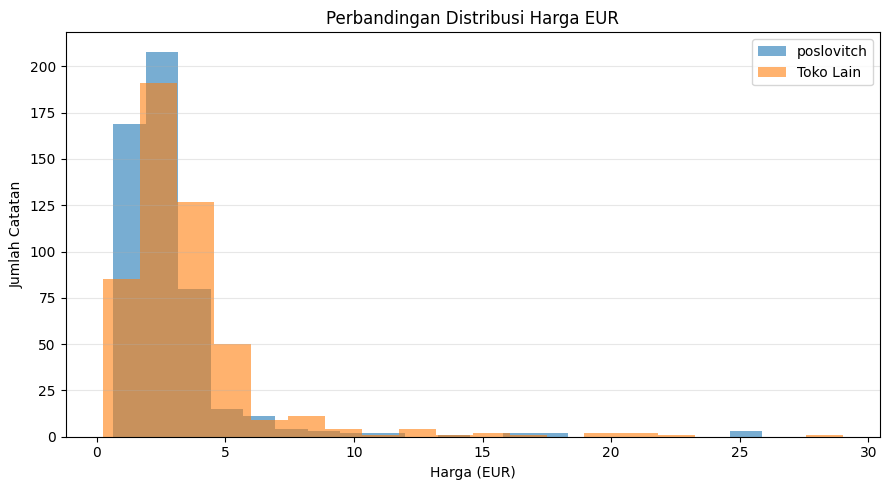

In [23]:
import matplotlib.pyplot as plt

# Ambil semua catatan harga EUR
data_eur = df[df["currency"] == "EUR"].copy()

# Kelompokkan catatan berdasarkan toko
data_eur["Kelompok Toko"] = data_eur["store_name"].apply(
    lambda toko: "poslovitch" if toko == "poslovitch" else "Toko Lain"
)

# Bandingkan distribusi harga
plt.figure(figsize=(9, 5))

for kelompok in ["poslovitch", "Toko Lain"]:
    harga = data_eur.loc[
        data_eur["Kelompok Toko"] == kelompok, "price"
    ]
    plt.hist(
        harga,
        bins=20,
        alpha=0.6,
        label=kelompok
    )

plt.title("Perbandingan Distribusi Harga EUR")
plt.xlabel("Harga (EUR)")
plt.ylabel("Jumlah Catatan")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

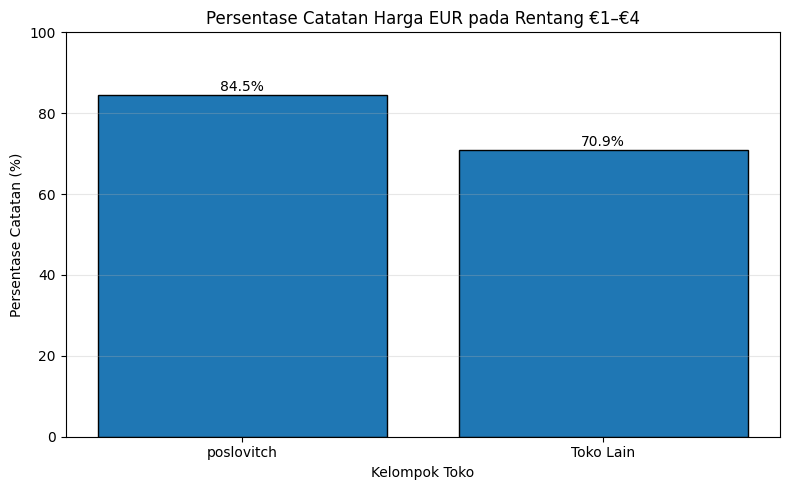

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Ambil seluruh catatan EUR
data_eur = df[df["currency"] == "EUR"].copy()

# Kelompokkan toko
data_eur["Kelompok Toko"] = data_eur["store_name"].apply(
    lambda toko: "poslovitch" if toko == "poslovitch" else "Toko Lain"
)

# Tandai catatan yang harganya €1–€4
data_eur["Harga €1–€4"] = (
    (data_eur["price"] >= 1) &
    (data_eur["price"] <= 4)
)

# Hitung persentase pada setiap kelompok
persentase = (
    data_eur.groupby("Kelompok Toko")["Harga €1–€4"]
    .mean()
    .mul(100)
    .reindex(["poslovitch", "Toko Lain"])
)

# Buat grafik
plt.figure(figsize=(8, 5))
bars = plt.bar(
    persentase.index,
    persentase.values,
    edgecolor="black"
)

plt.title("Persentase Catatan Harga EUR pada Rentang €1–€4")
plt.xlabel("Kelompok Toko")
plt.ylabel("Persentase Catatan (%)")
plt.ylim(0, 100)

# Tampilkan persentase di atas batang
for bar in bars:
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi + 1,
        f"{tinggi:.1f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

dari setiap 100 catatan EUR di poslovitch, sekitar 85 catatan berada pada rentang €1–€4. Sementara itu, pada kelompok toko lain, sekitar 71 dari setiap 100 catatan berada pada rentang tersebut.

In [25]:
# 1. Filter catatan EUR harga €1–€4 dari toko poslovitch
data_poslovitch = df[
    (df["currency"] == "EUR") &
    (df["price"] >= 1) &
    (df["price"] <= 4) &
    (df["store_name"] == "poslovitch")
].copy()

# 2. Hitung jumlah catatan untuk setiap kategori produk
jumlah_kategori = (
    data_poslovitch["category"]
    .dropna()
    .value_counts()
    .head(10)
    .rename_axis("Kategori Produk")
    .reset_index(name="Jumlah Catatan")
)

# 3. Tampilkan hasil
print("10 kategori produk terbanyak:")
display(jumlah_kategori)

# 4. Periksa kelengkapan data kategori
print("\nTotal catatan:", len(data_poslovitch))
print("Kategori terisi:", data_poslovitch["category"].notna().sum())
print("Kategori kosong:", data_poslovitch["category"].isna().sum())

10 kategori produk terbanyak:


,Kategori Produk,Jumlah Catatan



Total catatan: 424
Kategori terisi: 0
Kategori kosong: 424


In [26]:
# Tampilkan contoh nama produk dari poslovitch
display(
    data_poslovitch[
        ["product_name", "price"]
    ].head(20)
)

# Periksa jumlah nama produk yang tersedia
print(
    "Nama produk terisi:",
    data_poslovitch["product_name"].notna().sum()
)

print(
    "Nama produk kosong:",
    data_poslovitch["product_name"].isna().sum()
)

,product_name,price
22,BIO VILL FLAN NAPPE 4X125G,1.71
23,SOJASUN MYRTILLES 4 x 100g,1.69
24,HEINZ SCE AMERICAN BURG 230G,1.73
27,MAYO 5 ING SPL AMORA 235G,2.43
28,HARRYS BURGER NATURE 300G,1.55
29,SOIGNON BOITE LE CHEVRE 180G,2.91
31,HERTA LBV PAVE EPIN FR 180G GARDEN GOURMET,2.38
32,CHIPOLATAS VEGE/GOURMANDES 200G HAPPYVORE,3.71
33,TIPIAK MELI MELO GOURM 330G,2.24
34,MAYO CAM BOCAL BENEDICTA 250G,2.13


Nama produk terisi: 423
Nama produk kosong: 1


cenderung lebih banyak makanan

#### **membuat kategori produk berdasarkan nama produk**
karena kategori itu kosong maka dibuatkan kategori berdasarkan nama produk, kategori seperti roti/pastry, susu/keju, saus, makanan olahan, dan lainnya.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan data sudah difilter ke poslovitch dengan harga €1–€4
data_poslovitch = df[
    (df["currency"] == "EUR") &
    (df["price"] >= 1) &
    (df["price"] <= 4) &
    (df["store_name"] == "poslovitch")
].copy()

# Fungsi untuk mengelompokkan nama produk
def kategorikan_produk(nama):
    if pd.isna(nama):
        return "Nama tidak tersedia"

    nama = nama.lower()

    if any(kata in nama for kata in [
        "pain", "bread", "brot", "croissant", "brioche",
        "baguette", "burger bun", "toast"
    ]):
        return "Roti dan pastry"

    elif any(kata in nama for kata in [
        "lait", "milk", "chevre", "chèvre", "gouda",
        "fromage", "cheese", "yaourt", "yogurt", "beurre"
    ]):
        return "Susu dan olahannya"

    elif any(kata in nama for kata in [
        "mayo", "sauce", "sauce", "ketchup", "mustard"
    ]):
        return "Saus dan pelengkap"

    elif any(kata in nama for kata in [
        "saucisse", "chipolata", "jambon", "porc",
        "poulet", "boeuf", "beef", "chicken", "viande"
    ]):
        return "Daging dan olahannya"

    elif any(kata in nama for kata in [
        "choco", "chocolat", "biscuit", "cookie",
        "bonbon", "gateau", "gâteau"
    ]):
        return "Camilan dan makanan manis"

    elif any(kata in nama for kata in [
        "salade", "tomate", "pomme", "banane", "carotte",
        "legume", "légume", "fruit", "apple", "banana"
    ]):
        return "Buah dan sayuran"

    else:
        return "Lainnya"

# Terapkan kategori pada nama produk
data_poslovitch["Kategori Analisis"] = (
    data_poslovitch["product_name"].apply(kategorikan_produk)
)

# Hitung jumlah catatan per kategori
hasil_kategori = (
    data_poslovitch["Kategori Analisis"]
    .value_counts()
    .rename_axis("Kategori Produk")
    .reset_index(name="Jumlah Catatan")
)

display(hasil_kategori)

,Kategori Produk,Jumlah Catatan
0,Lainnya,296
1,Saus dan pelengkap,32
2,Roti dan pastry,28
3,Susu dan olahannya,23
4,Buah dan sayuran,20
5,Daging dan olahannya,14
6,Camilan dan makanan manis,10
7,Nama tidak tersedia,1


In [28]:
display(
    data_poslovitch.loc[
        data_poslovitch["Kategori Analisis"] == "Lainnya",
        ["product_name", "price"]
    ].head(30)
)

,product_name,price
22,BIO VILL FLAN NAPPE 4X125G,1.71
23,SOJASUN MYRTILLES 4 x 100g,1.69
24,HEINZ SCE AMERICAN BURG 230G,1.73
28,HARRYS BURGER NATURE 300G,1.55
31,HERTA LBV PAVE EPIN FR 180G GARDEN GOURMET,2.38
33,TIPIAK MELI MELO GOURM 330G,2.24
36,R&R CASSOUL TOULOUSE 420G RAYNAL ET ROQUELAURE,3.04
41,VIENNOIS CAFE 4X100G,1.57
44,"VEGE, SAUC.VEGET.X4,200G",2.12
46,FIND PETITS TRESORS 450G,3.34


In [29]:

def kategorikan_produk(nama):
    if pd.isna(nama):
        return "Nama tidak tersedia"

    nama = nama.lower()

    # 1. Produk berbasis kedelai / alternatif nabati
    if any(k in nama for k in [
        "soja", "sojasun", "garden gourmet",
        "vege", "veget", "vegetal"
    ]):
        return "Produk berbasis kedelai/nabati"

    # 2. Ikan dan hasil laut
    elif any(k in nama for k in [
        "filet colin", "saumon", "thon",
        "poisson", "crevette", "sardine"
    ]):
        return "Ikan dan hasil laut"

    # 3. Roti dan pastry
    elif any(k in nama for k in [
        "pain", "bread", "brot", "croissant",
        "brioche", "bagel", "muffin", "baguette",
        "toast", "harry's burger", "burger nature"
    ]):
        return "Roti dan pastry"

    # 4. Saus dan pelengkap
    elif any(k in nama for k in [
        "mayo", "sauce", "sce", "ketchup",
        "mustard", "amora", "heinz", "tapenade"
    ]):
        return "Saus dan pelengkap"

    # 5. Buah dan sayuran
    elif any(k in nama for k in [
        "salade", "tomate", "pomme", "banane",
        "carotte", "legume", "légume", "fruit",
        "mais doux", "haricot", "macedoine",
        "ble tendre", "perle ble"
    ]):
        return "Buah dan sayuran"

    # 6. Daging dan olahannya
    elif any(k in nama for k in [
        "saucisse", "chipolata", "jambon", "porc",
        "poulet", "boeuf", "beef", "chicken",
        "viande", "steak", "merguez", "cassoul"
    ]):
        return "Daging dan olahannya"

    # 7. Susu dan olahannya
    elif any(k in nama for k in [
        "lait", "milk", "chevre", "chèvre",
        "gouda", "fromage", "cheese", "yaourt",
        "yogurt", "beurre", "st moret",
        "rondel", "tartare", "soignon"
    ]):
        return "Susu dan olahannya"

    # 8. Camilan dan makanan manis
    elif any(k in nama for k in [
        "choco", "chocolat", "biscuit", "cookie",
        "bonbon", "gateau", "gâteau", "flan",
        "viennois", "petits tresors", "find"
    ]):
        return "Camilan dan makanan manis"

    else:
        return "Lainnya"


data_poslovitch["Kategori Analisis"] = (
    data_poslovitch["product_name"].apply(kategorikan_produk)
)

hasil_kategori = (
    data_poslovitch["Kategori Analisis"]
    .value_counts()
    .rename_axis("Kategori Produk")
    .reset_index(name="Jumlah Catatan")
)

hasil_kategori["Persentase (%)"] = (
    hasil_kategori["Jumlah Catatan"] /
    len(data_poslovitch) * 100
).round(2)

display(hasil_kategori)


,Kategori Produk,Jumlah Catatan,Persentase (%)
0,Lainnya,215,50.71
1,Saus dan pelengkap,40,9.43
2,Roti dan pastry,37,8.73
3,Produk berbasis kedelai/nabati,35,8.25
4,Susu dan olahannya,30,7.08
5,Buah dan sayuran,25,5.90
6,Camilan dan makanan manis,21,4.95
7,Daging dan olahannya,17,4.01
8,Ikan dan hasil laut,3,0.71
9,Nama tidak tersedia,1,0.24


### **Catatan Mata uang tiap negara**

In [30]:

ringkasan_mata_uang = (
    df.groupby("currency")["price"]
    .agg(
        jumlah_catatan="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .round(2)
    .sort_values("jumlah_catatan", ascending=False)
)

display(ringkasan_mata_uang)


,jumlah_catatan,rata_rata,median,minimum,maksimum,Q1,Q3
currency,,,,,,,
EUR,994,3.20,2.50,0.23,29.01,1.79,3.69
USD,407,10.88,9.49,0.50,43.99,5.99,14.99
NOK,190,34.93,31.70,9.90,139.90,22.75,40.48
BAM,122,4.35,2.47,0.29,27.99,1.49,5.86
SEK,118,23.97,22.90,5.90,61.46,16.13,28.29
CZK,73,73.13,35.90,9.90,319.00,23.90,59.90
KZT,35,1047.31,779.00,110.00,5030.00,362.00,1450.00
PLN,21,9.80,5.79,1.97,42.30,3.99,14.19
SGD,16,3.32,2.88,1.60,8.79,1.96,4.16


#### **membandingkan tingkat penyebaran harga pada enam mata uang dengan jumlah catatan terbanyak.**

In [31]:

# Memilih 6 mata uang dengan jumlah catatan terbanyak
mata_uang_utama = ["EUR", "USD", "NOK", "BAM", "SEK", "CZK"]

data_utama = df[df["currency"].isin(mata_uang_utama)]

# Menghitung rentang dan rentang antarkuartil (IQR)
ringkasan_sebaran = (
    data_utama.groupby("currency")["price"]
    .agg(
        jumlah_catatan="count",
        minimum="min",
        Q1=lambda x: x.quantile(0.25),
        median="median",
        Q3=lambda x: x.quantile(0.75),
        maksimum="max"
    )
)

ringkasan_sebaran["rentang"] = (
    ringkasan_sebaran["maksimum"] -
    ringkasan_sebaran["minimum"]
)

ringkasan_sebaran["IQR"] = (
    ringkasan_sebaran["Q3"] -
    ringkasan_sebaran["Q1"]
)

display(ringkasan_sebaran.round(2))


,jumlah_catatan,minimum,Q1,median,Q3,maksimum,rentang,IQR
currency,,,,,,,,
BAM,122,0.29,1.49,2.47,5.86,27.99,27.70,4.38
CZK,73,9.90,23.90,35.90,59.90,319.00,309.10,36.00
EUR,994,0.23,1.79,2.50,3.69,29.01,28.78,1.90
NOK,190,9.90,22.75,31.70,40.48,139.90,130.00,17.73
SEK,118,5.90,16.13,22.90,28.29,61.46,55.56,12.16
USD,407,0.50,5.99,9.49,14.99,43.99,43.49,9.00


In [32]:

# Mengambil seluruh catatan harga EUR
harga_eur = df.loc[df["currency"] == "EUR", "price"]

# Menghitung batas atas untuk mendeteksi kandidat pencilan
Q1 = harga_eur.quantile(0.25)
Q3 = harga_eur.quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Menghitung catatan di luar batas
kandidat_pencilan = harga_eur[
    (harga_eur < batas_bawah) |
    (harga_eur > batas_atas)
]

print("Jumlah catatan EUR:", len(harga_eur))
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Batas bawah:", round(batas_bawah, 2))
print("Batas atas:", round(batas_atas, 2))
print("Jumlah kandidat pencilan:", len(kandidat_pencilan))
print("Persentase kandidat pencilan:",
      round(len(kandidat_pencilan) / len(harga_eur) * 100, 2), "%")


Jumlah catatan EUR: 994
Q1: 1.79
Q3: 3.69
IQR: 1.9
Batas bawah: -1.06
Batas atas: 6.54
Jumlah kandidat pencilan: 54
Persentase kandidat pencilan: 5.43 %


### **USD**
mengeksplorasi pola distribusi harga USD sebagai analisis tambahan

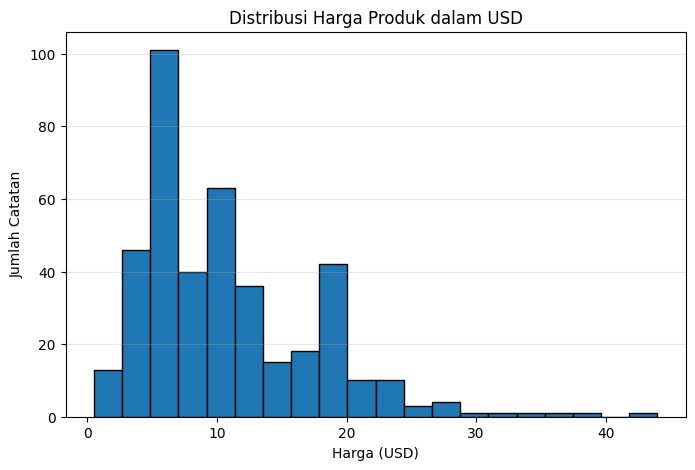

In [33]:
import matplotlib.pyplot as plt

harga_usd = df.loc[df["currency"] == "USD", "price"]

plt.figure(figsize=(8, 5))
plt.hist(harga_usd, bins=20, edgecolor="black")

plt.title("Distribusi Harga Produk dalam USD")
plt.xlabel("Harga (USD)")
plt.ylabel("Jumlah Catatan")
plt.grid(axis="y", alpha=0.3)

plt.show()

Distribusi harga produk dalam USD menunjukkan konsentrasi catatan harga pada rentang USD 4–12, dengan konsentrasi tertinggi sekitar USD 4–6. Distribusi menceng ke kanan, dengan sebagian kecil catatan memiliki harga yang lebih tinggi hingga sekitar USD 44. Terdapat pula konsentrasi harga lain di sekitar USD 17–20 yang perlu ditelusuri lebih lanjut.

In [34]:
harga_usd = df.loc[df["currency"] == "USD", "price"]

harga_usd.describe()

,price
count,407.000000
mean,10.877740
std,6.740386
min,0.500000
25%,5.990000
50%,9.490000
75%,14.990000
max,43.990000


median harga USD sebesar $9,49, sedangkan rata-ratanya $10,88. Rata-rata yang lebih tinggi daripada median, ditambah bentuk histogram, mendukung indikasi bahwa distribusi harga menceng ke kanan. Sebagian kecil harga yang tinggi dapat ikut menaikkan rata-rata.
Batang tertinggi terlihat berada di kisaran $4–$6, dengan jumlah catatan sekitar 100.

#### **mengecek apakah data EUR dan USD punya produk yang sama atau bisa dibandingkan berdasarkan nama produknya**

In [35]:
# Mengambil nama produk yang tercatat dalam EUR dan USD
produk_eur = set(
    df.loc[df["currency"] == "EUR", "product_name"]
    .dropna()
    .str.strip()
    .str.lower()
)

produk_usd = set(
    df.loc[df["currency"] == "USD", "product_name"]
    .dropna()
    .str.strip()
    .str.lower()
)

# Mencari nama produk yang muncul pada kedua kelompok
produk_sama = produk_eur.intersection(produk_usd)

print("Jumlah produk unik EUR:", len(produk_eur))
print("Jumlah produk unik USD:", len(produk_usd))
print("Jumlah nama produk yang muncul di keduanya:", len(produk_sama))
print("Contoh nama produk yang sama:", list(produk_sama)[:10])

Jumlah produk unik EUR: 818
Jumlah produk unik USD: 402
Jumlah nama produk yang muncul di keduanya: 0
Contoh nama produk yang sama: []


#### **Analisis harga berdasarkan rentang waktu**
Tujuannya untuk mengetahui apakah data harga EUR atau USD memiliki rentang waktu yang cukup untuk melihat perubahan harga.

In [36]:
df["date_recorded"] = pd.to_datetime(
    df["date_recorded"], errors="coerce"
)

print("Tanggal paling awal:", df["date_recorded"].min())
print("Tanggal paling akhir:", df["date_recorded"].max())

print("\nJumlah catatan tanggal EUR dan USD:")
print(
    df[df["currency"].isin(["EUR", "USD"])]
    .groupby("currency")["date_recorded"]
    .agg(["count", "min", "max"])
)

Tanggal paling awal: 2026-02-07 00:00:00
Tanggal paling akhir: 2026-10-03 00:00:00

Jumlah catatan tanggal EUR dan USD:
          count        min        max
currency                             
EUR         994 2026-09-12 2026-10-03
USD         407 2026-02-07 2026-10-02


In [37]:
# Menghitung jumlah catatan dan median harga per bulan
data_usd = df[df["currency"] == "USD"].copy()

data_usd["bulan"] = data_usd["date_recorded"].dt.to_period("M")

ringkasan_usd_bulanan = (
    data_usd.groupby("bulan")["price"]
    .agg(jumlah_catatan="count", median_harga="median")
    .reset_index()
)

ringkasan_usd_bulanan

,bulan,jumlah_catatan,median_harga
0,2026-02,15,4.99
1,2026-09,325,8.49
2,2026-10,67,11.84


In [38]:
data_usd = df[df["currency"] == "USD"].copy()

produk_per_bulan = (
    data_usd.dropna(subset=["product_name"])
    .groupby(data_usd["date_recorded"].dt.to_period("M"))["product_name"]
    .nunique()
    .reset_index(name="jumlah_produk_unik")
    .rename(columns={"date_recorded": "bulan"})
)

produk_per_bulan

,bulan,jumlah_produk_unik
0,2026-02,15
1,2026-09,322
2,2026-10,66


sebagian besar catatan pada bulan yang sama berasal dari nama produk yang berbeda. Namun, ini belum menjelaskan apakah produk-produk tersebut sama atau berbeda antarbulan.

In [39]:
data_usd = df[df["currency"] == "USD"].copy()

data_usd["bulan"] = data_usd["date_recorded"].dt.to_period("M")

produk_bulanan = (
    data_usd.dropna(subset=["product_name"])
    .assign(
        product_name=lambda x: x["product_name"].str.strip().str.lower()
    )
    .groupby("product_name")["bulan"]
    .nunique()
)

produk_muncul_berulang = produk_bulanan[produk_bulanan > 1]

print("Jumlah nama produk yang muncul di lebih dari satu bulan:",
      len(produk_muncul_berulang))

Jumlah nama produk yang muncul di lebih dari satu bulan: 1


### **VISUALISASI**

#### boxplot (distribusi)

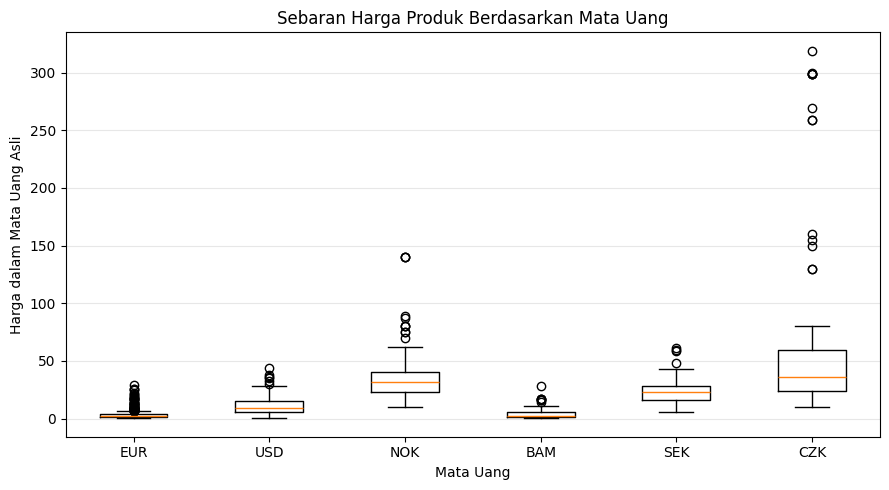

In [40]:
import matplotlib.pyplot as plt

mata_uang_utama = ["EUR", "USD", "NOK", "BAM", "SEK", "CZK"]

data_boxplot = [
    df.loc[df["currency"] == mata_uang, "price"].dropna()
    for mata_uang in mata_uang_utama
]

plt.figure(figsize=(9, 5))
plt.boxplot(data_boxplot, tick_labels=mata_uang_utama)

plt.title("Sebaran Harga Produk Berdasarkan Mata Uang")
plt.xlabel("Mata Uang")
plt.ylabel("Harga dalam Mata Uang Asli")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Visualisasi boxplot menunjukkan bahwa sebaran harga produk bervariasi pada setiap mata uang. Sebagian besar catatan harga terkonsentrasi pada rentang tertentu, tetapi terdapat pula sejumlah catatan harga ekstrem di luar whisker. Temuan ini menunjukkan adanya variasi harga dalam dataset. Namun, perbandingan nominal antar mata uang tidak dapat digunakan secara langsung untuk menentukan pasar yang lebih mahal karena perbedaan satuan mata uang dan belum adanya kepastian bahwa produk yang dibandingkan setara. Oleh karena itu, data ini dapat digunakan untuk memahami distribusi harga, tetapi masih memerlukan informasi tambahan sebelum dijadikan dasar penetapan harga di pasar baru.

#### persentase kelengkapan produk (berdasarkan dataset asli)

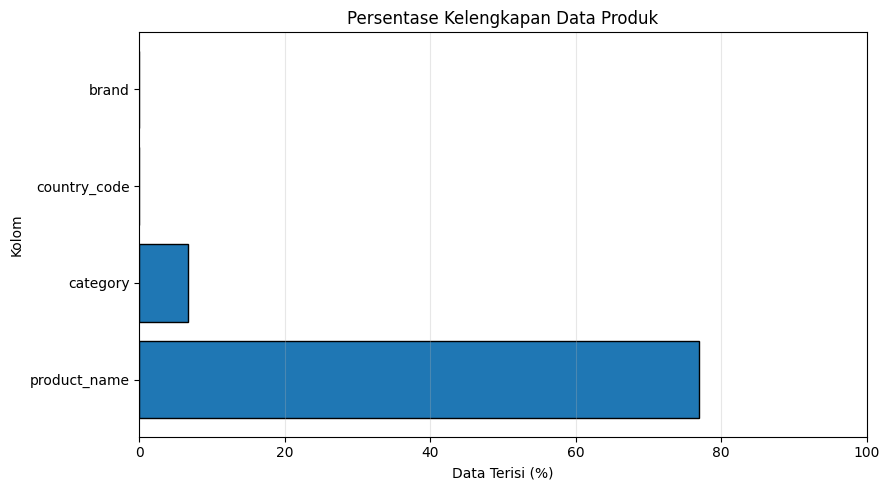

In [41]:
import matplotlib.pyplot as plt

kolom_penting = ["country_code", "category", "brand", "product_name"]

persentase_kosong = (
    df[kolom_penting]
    .isnull()
    .mean()
    .mul(100)
    .sort_values()
)

persentase_terisi = 100 - persentase_kosong

plt.figure(figsize=(9, 5))

plt.barh(
    persentase_terisi.index,
    persentase_terisi.values,
    edgecolor="black"
)

plt.title("Persentase Kelengkapan Data Produk")
plt.xlabel("Data Terisi (%)")
plt.ylabel("Kolom")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Grafik persentase kelengkapan data menunjukkan bahwa kolom nama produk memiliki tingkat kelengkapan sebesar 76,9%, sedangkan kolom kategori hanya 6,7%. Kolom merek dan kode negara tidak memiliki data yang terisi. Kondisi ini membatasi analisis harga berdasarkan jenis produk, merek, dan negara. Oleh karena itu, dataset dapat digunakan untuk menggambarkan distribusi harga, tetapi diperlukan pelengkapan data agar hasil analisis dapat menjadi dasar penetapan harga yang lebih tepat untuk pasar baru.

#### visualisasi catatan harga berdasarkan mata uang

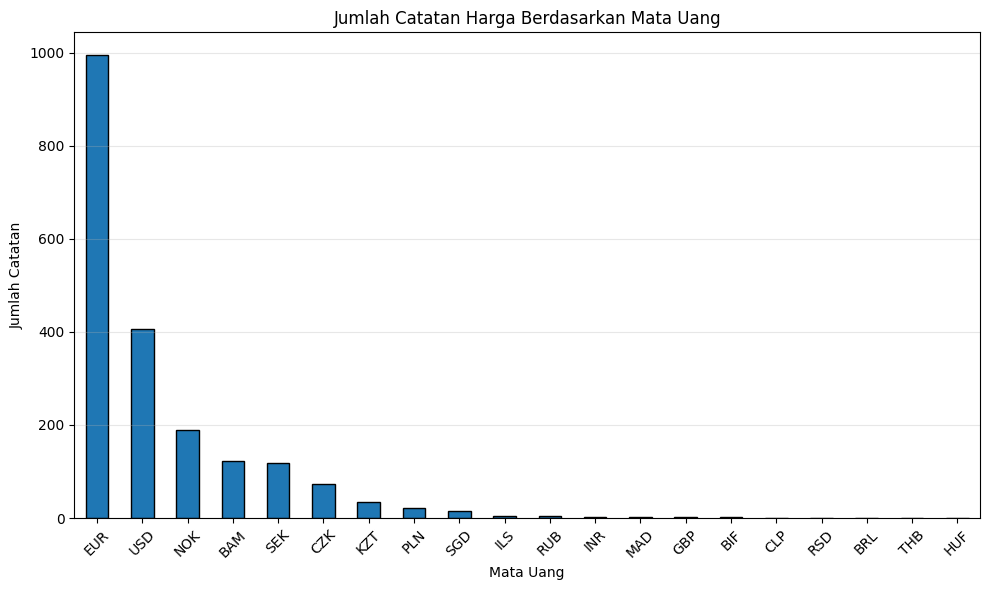

In [42]:
import matplotlib.pyplot as plt

jumlah_mata_uang = df["currency"].value_counts()

plt.figure(figsize=(10, 6))

jumlah_mata_uang.plot(kind="bar", edgecolor="black")

plt.title("Jumlah Catatan Harga Berdasarkan Mata Uang")
plt.xlabel("Mata Uang")
plt.ylabel("Jumlah Catatan")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Visualisasi jumlah catatan harga berdasarkan mata uang menunjukkan bahwa data didominasi oleh EUR sebanyak 994 catatan (49,7%) dan USD sebanyak 407 catatan (20,35%). Enam mata uang dengan jumlah catatan terbanyak mencakup 95,2% dari keseluruhan dataset. Hal ini menunjukkan bahwa analisis distribusi harga dapat lebih difokuskan pada mata uang dengan jumlah catatan yang memadai, sedangkan interpretasi untuk mata uang dengan catatan sangat sedikit perlu dilakukan secara hati-hati. Meskipun demikian, jumlah catatan tidak menjamin keterwakilan pasar secara keseluruhan.

#### Jumlah Catatan Produk per Kategori (dari toko poslovitch)

In [43]:
print(data_poslovitch.columns.tolist())

['price_record_id', 'product_code', 'product_name', 'brand', 'category', 'price', 'currency', 'price_is_discounted', 'store_name', 'city', 'country_code', 'date_recorded', 'Kategori Analisis']


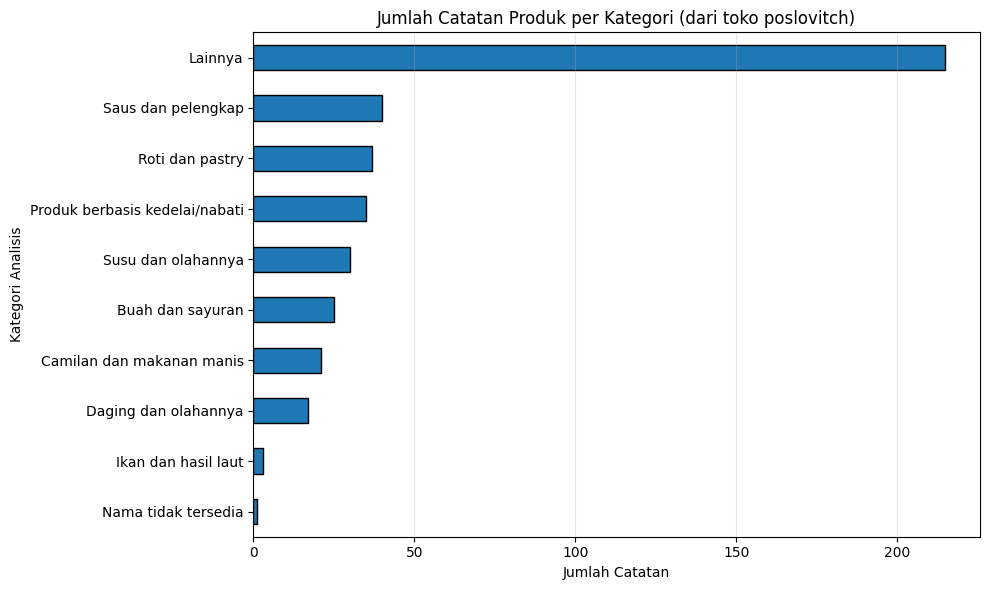

In [44]:
import matplotlib.pyplot as plt

jumlah_kategori = (
    data_poslovitch["Kategori Analisis"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))
jumlah_kategori.plot(kind="barh", edgecolor="black")

plt.title("Jumlah Catatan Produk per Kategori (dari toko poslovitch)")
plt.xlabel("Jumlah Catatan")
plt.ylabel("Kategori Analisis")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Visualisasi jumlah catatan produk berdasarkan kategori menunjukkan bahwa kategori “Lainnya” mendominasi dengan 215 catatan (50,71%). Sementara itu, kategori spesifik terbanyak adalah saus dan pelengkap sebanyak 40 catatan, diikuti roti dan pastry sebanyak 37 catatan. Dominasi kategori “Lainnya” mengindikasikan bahwa klasifikasi berdasarkan kata kunci nama produk belum cukup spesifik. Oleh karena itu, klasifikasi perlu diperbaiki sebelum data digunakan untuk membandingkan harga antarjenis produk. Temuan ini terbatas pada 424 catatan berdenominasi EUR dengan harga €1–€4 dari toko `poslovitch`, sehingga belum dapat digeneralisasi ke seluruh dataset atau pasar.

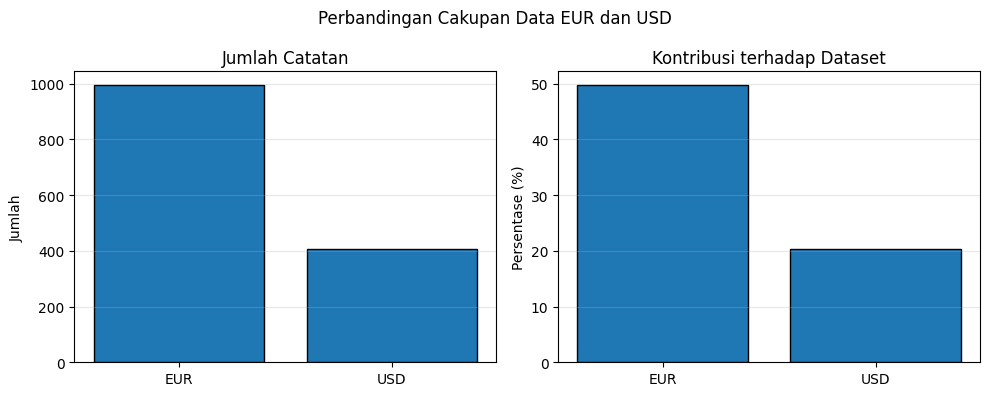

In [45]:
import matplotlib.pyplot as plt

mata_uang = ["EUR", "USD"]

jumlah = df["currency"].value_counts().reindex(mata_uang)
persentase = jumlah / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(jumlah.index, jumlah.values, edgecolor="black")
axes[0].set_title("Jumlah Catatan")
axes[0].set_ylabel("Jumlah")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(persentase.index, persentase.values, edgecolor="black")
axes[1].set_title("Kontribusi terhadap Dataset")
axes[1].set_ylabel("Persentase (%)")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Perbandingan Cakupan Data EUR dan USD")
plt.tight_layout()
plt.show()

### **Analisis Tambahan**

#### **Analisa perbandingan harga antar-toko dalam kelompok EUR.**

In [46]:
data_eur = df[df["currency"] == "EUR"].copy()

toko_teratas = (
    data_eur["store_name"]
    .value_counts()
    .head(5)
)

print("Lima toko dengan catatan EUR terbanyak:")
print(toko_teratas)

Lima toko dengan catatan EUR terbanyak:
store_name
poslovitch       502
sebleouf         193
tartelette299     52
stephane          36
jangop            22
Name: count, dtype: int64


In [47]:
# Ambil data EUR dari 5 toko dengan catatan terbanyak
toko_terpilih = toko_teratas.index.tolist()

data_eur_5_toko = data_eur[
    data_eur["store_name"].isin(toko_terpilih)
].copy()

# Bersihkan nama produk agar perbedaan huruf besar/kecil
# dan spasi tidak dianggap sebagai produk berbeda
data_eur_5_toko["nama_produk_bersih"] = (
    data_eur_5_toko["product_name"]
    .dropna()
    .str.strip()
    .str.lower()
)

# Hitung berapa toko berbeda yang mencatat setiap nama produk
jumlah_toko_per_produk = (
    data_eur_5_toko.dropna(subset=["nama_produk_bersih"])
    .groupby("nama_produk_bersih")["store_name"]
    .nunique()
)

produk_lintas_toko = jumlah_toko_per_produk[
    jumlah_toko_per_produk > 1
]

print("Jumlah nama produk yang muncul di lebih dari satu toko:",
      len(produk_lintas_toko))

Jumlah nama produk yang muncul di lebih dari satu toko: 2


In [48]:
# Tampilkan nama produk yang muncul di lebih dari satu toko
print("Nama produk yang muncul di beberapa toko:")
print(produk_lintas_toko)

# Tampilkan detail toko, harga, dan tanggal pencatatan
data_produk_sama = data_eur_5_toko[
    data_eur_5_toko["nama_produk_bersih"].isin(
        produk_lintas_toko.index
    )
][
    ["store_name", "product_name", "price", "date_recorded"]
].sort_values(["product_name", "store_name"])

display(data_produk_sama)

Nama produk yang muncul di beberapa toko:
nama_produk_bersih
hpyre tranche tomate herbes    2
nems hache vegetal 120g        2
Name: store_name, dtype: int64


,store_name,product_name,price,date_recorded
324,stephane,HPYRE TRANCHE TOMATE HERBES,3.39,2026-10-03
262,tartelette299,HPYRE TRANCHE TOMATE HERBES,3.39,2026-10-03
310,stephane,NEMS HACHE VEGETAL 120G,3.39,2026-10-03
260,tartelette299,NEMS HACHE VEGETAL 120G,3.39,2026-10-03


In [49]:
# Ambil data category yang tidak kosong
kategori_terisi = df["category"].dropna()

print("Jumlah data category yang terisi:", len(kategori_terisi))
print("\nDaftar kategori dan jumlah datanya:")
print(kategori_terisi.value_counts())

Jumlah data category yang terisi: 134

Daftar kategori dan jumlah datanya:
category
en:breads                 12
en:microwave-meals         9
en:pastries                7
en:yogurts                 6
en:ice-creams              5
                          ..
en:peanuts                 1
fr:pains-multicereales     1
en:black-grapes            1
en:scallions               1
en:cucumbers               1
Name: count, Length: 64, dtype: int64


hasilnya menunjukkan keterbatasan data.

#### **Analisis kategori produk pada seluruh catatan EUR**

In [50]:
# 1. Ambil seluruh catatan dengan mata uang EUR
data_eur_semua = df[df["currency"] == "EUR"].copy()

# 2. Terapkan kategorisasi berdasarkan nama produk
data_eur_semua["Kategori Analisis"] = (
    data_eur_semua["product_name"].apply(kategorikan_produk)
)

# 3. Hitung jumlah catatan setiap kategori
hasil_kategori_eur = (
    data_eur_semua["Kategori Analisis"]
    .value_counts()
    .rename_axis("Kategori Produk")
    .reset_index(name="Jumlah Catatan")
)

# 4. Hitung persentase
hasil_kategori_eur["Persentase (%)"] = (
    hasil_kategori_eur["Jumlah Catatan"] /
    len(data_eur_semua) * 100
).round(2)

display(hasil_kategori_eur)

,Kategori Produk,Jumlah Catatan,Persentase (%)
0,Lainnya,515,51.81
1,Nama tidak tersedia,161,16.20
2,Produk berbasis kedelai/nabati,59,5.94
3,Buah dan sayuran,50,5.03
4,Saus dan pelengkap,49,4.93
5,Roti dan pastry,44,4.43
6,Susu dan olahannya,41,4.12
7,Daging dan olahannya,34,3.42
8,Camilan dan makanan manis,30,3.02
9,Ikan dan hasil laut,11,1.11


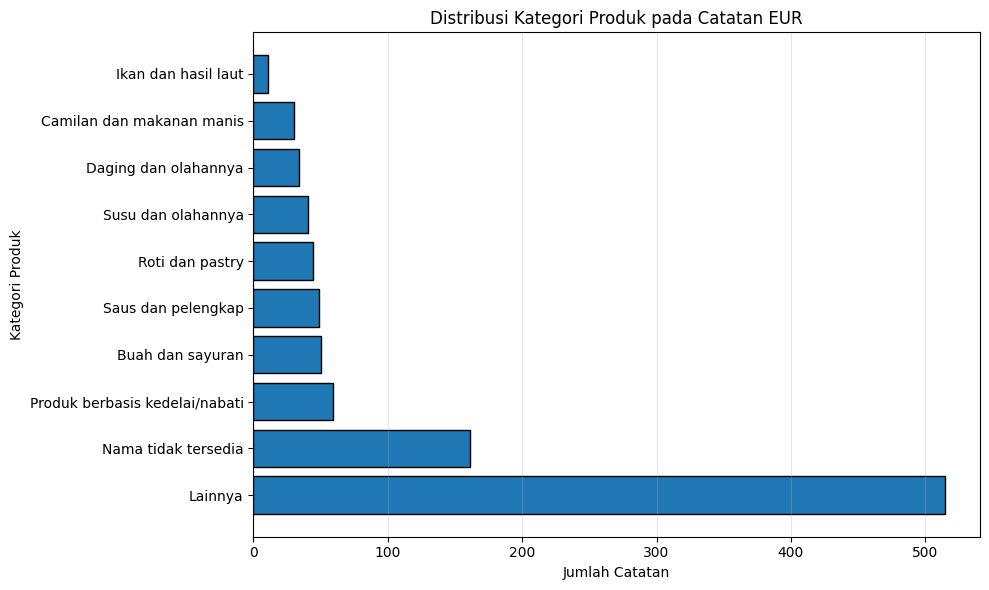

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    hasil_kategori_eur["Kategori Produk"],
    hasil_kategori_eur["Jumlah Catatan"],
    edgecolor="black"
)

plt.title("Distribusi Kategori Produk pada Catatan EUR")
plt.xlabel("Jumlah Catatan")
plt.ylabel("Kategori Produk")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### **Membandingkan kategori produk EUR dan USD**

In [52]:
# 1. Ambil data EUR dan USD
data_eur_usd = df[
    df["currency"].isin(["EUR", "USD"])
].copy()

# 2. Terapkan kategorisasi
data_eur_usd["Kategori Analisis"] = (
    data_eur_usd["product_name"].apply(kategorikan_produk)
)

# 3. Buat tabel perbandingan
perbandingan_kategori = pd.crosstab(
    data_eur_usd["Kategori Analisis"],
    data_eur_usd["currency"]
)

# 4. Tambahkan persentase per mata uang
persentase_kategori = (
    perbandingan_kategori.div(
        perbandingan_kategori.sum(axis=0),
        axis=1
    ) * 100
).round(2)

print("Jumlah catatan produk:")
display(perbandingan_kategori)

print("Persentase kategori pada setiap mata uang:")
display(persentase_kategori)

Jumlah catatan produk:


currency,EUR,USD
Kategori Analisis,,
Buah dan sayuran,50,2
Camilan dan makanan manis,30,8
Daging dan olahannya,34,12
Ikan dan hasil laut,11,0
Lainnya,515,340
Nama tidak tersedia,161,1
Produk berbasis kedelai/nabati,59,1
Roti dan pastry,44,8
Saus dan pelengkap,49,23


Persentase kategori pada setiap mata uang:


currency,EUR,USD
Kategori Analisis,,
Buah dan sayuran,5.03,0.49
Camilan dan makanan manis,3.02,1.97
Daging dan olahannya,3.42,2.95
Ikan dan hasil laut,1.11,0.00
Lainnya,51.81,83.54
Nama tidak tersedia,16.20,0.25
Produk berbasis kedelai/nabati,5.94,0.25
Roti dan pastry,4.43,1.97
Saus dan pelengkap,4.93,5.65


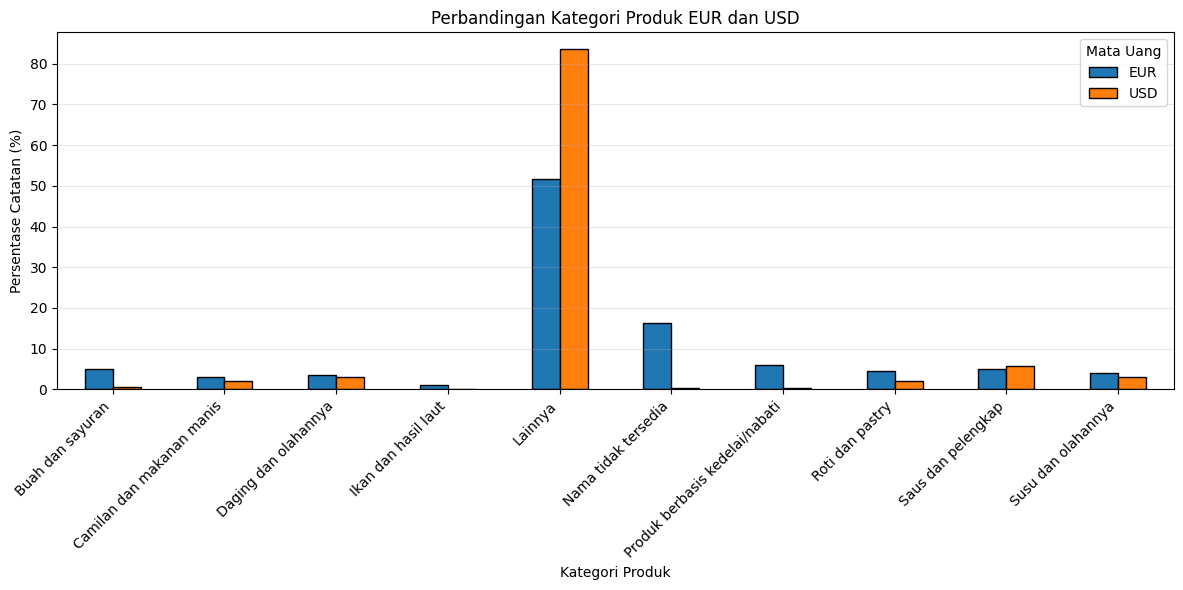

In [53]:
persentase_kategori.plot(
    kind="bar",
    figsize=(12, 6),
    edgecolor="black"
)

plt.title("Perbandingan Kategori Produk EUR dan USD")
plt.xlabel("Kategori Produk")
plt.ylabel("Persentase Catatan (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Mata Uang")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### **Melihat 10 produk dengan catatan terbanyak pada EUR dan USD**

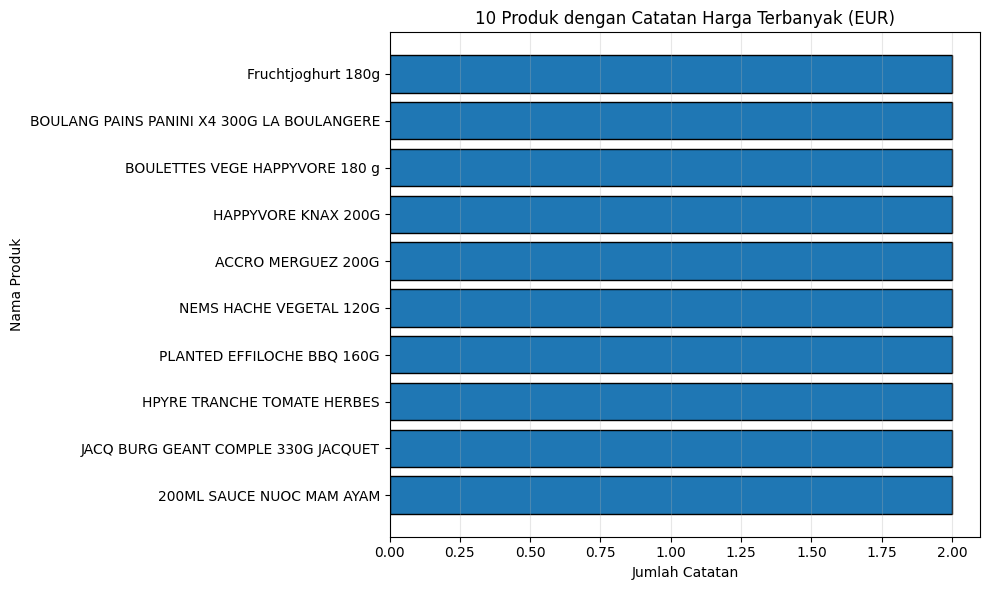

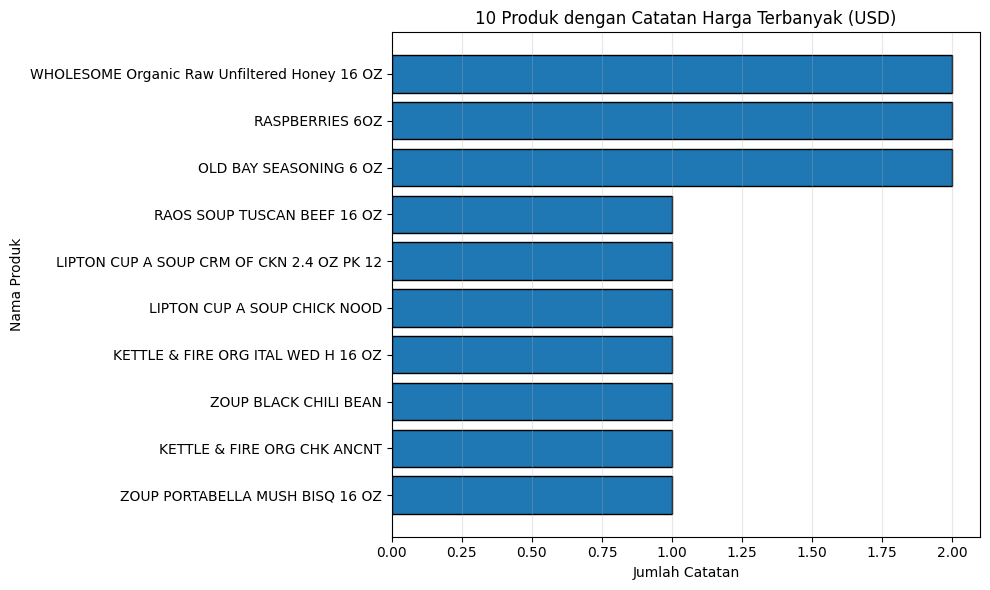

In [54]:
for mata_uang in ["EUR", "USD"]:

    data_produk = df[df["currency"] == mata_uang]

    produk_teratas = (
        data_produk["product_name"]
        .dropna()
        .value_counts()
        .head(10)
        .sort_values()
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        produk_teratas.index,
        produk_teratas.values,
        edgecolor="black"
    )

    plt.title(f"10 Produk dengan Catatan Harga Terbanyak ({mata_uang})")
    plt.xlabel("Jumlah Catatan")
    plt.ylabel("Nama Produk")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

#### **Pemeriksaan kolom diskon**

In [55]:
# Periksa status diskon pada catatan EUR
data_diskon_eur = df[df["currency"] == "EUR"]

hasil_diskon = (
    data_diskon_eur["price_is_discounted"]
    .value_counts()
    .rename_axis("Status Diskon")
    .reset_index(name="Jumlah Catatan")
)

hasil_diskon["Persentase (%)"] = (
    hasil_diskon["Jumlah Catatan"] /
    len(data_diskon_eur) * 100
).round(2)

display(hasil_diskon)

,Status Diskon,Jumlah Catatan,Persentase (%)
0,False,994,100.0


## [FASE INFORMASI STRATEGIS]: Analisis Pola Produk dan Pengambilan Keputusan Bisnis (*Strategic Business Insights & Actionable Business Decisions*) **bold text**

Berdasarkan hasil analisis data, diperoleh beberapa informasi strategis yang dapat digunakan sebagai bahan pertimbangan dalam pengelolaan produk dan harga. Analisis ini berfokus pada pola catatan harga berdasarkan kelompok mata uang, komposisi kategori produk, serta kualitas informasi yang tersedia dalam dataset.

## 1. Strategi Fokus Pengamatan Berdasarkan Kelompok Mata Uang (*Currency-Based Market Observation*)

**Informasi yang ditemukan:**

- EUR memiliki 994 catatan atau 49,7% dari keseluruhan dataset.
- USD memiliki 407 catatan atau 20,35%.
- Kedua mata uang tersebut mencakup sekitar 70,05% dari keseluruhan catatan harga.

**Informasi Strategis:**

EUR merupakan kelompok mata uang dengan jumlah catatan harga terbanyak dalam dataset. Oleh karena itu, kelompok EUR dapat dijadikan fokus utama untuk mengamati karakteristik harga dan kategori produk. Sementara itu, USD dapat digunakan sebagai kelompok pembanding untuk melihat perbedaan pola produk dan harga yang tercatat.

**Keputusan Bisnis:**

Pengelola bisnis dapat menerapkan dua prioritas pengamatan:

1. **Prioritas pertama — EUR:** Memantau karakteristik harga dan kategori produk yang tercatat pada kelompok EUR.
2. **Prioritas kedua — USD:** Melakukan analisis pembanding untuk mengetahui perbedaan karakteristik harga dan komposisi kategori produk.

Analisis harga pada masing-masing mata uang sebaiknya tetap dilakukan secara terpisah. Konversi mata uang tidak perlu dilakukan secara langsung karena perbandingan nominal harga tanpa memperhitungkan nilai tukar pada tanggal pencatatan dapat menghasilkan interpretasi yang kurang tepat.

---

## 2. Prioritas Pengamatan Kategori Produk (*Product Category Focus*)

**Informasi yang ditemukan:**

Berdasarkan hasil pengelompokan kategori produk pada seluruh catatan EUR menggunakan klasifikasi berdasarkan kata kunci nama produk, diperoleh hasil sebagai berikut:

- Produk berbasis kedelai/nabati: 59 catatan (5,94%).
- Buah dan sayuran: 50 catatan (5,03%).
- Saus dan pelengkap: 49 catatan (4,93%).
- Kategori Lainnya: 515 catatan (51,81%).
- Nama tidak tersedia: 161 catatan (16,20%).

**Informasi Strategis:**

Produk berbasis kedelai/nabati menjadi kategori dengan jumlah catatan terbanyak di antara kategori yang berhasil dikenali pada kelompok EUR. Selain itu, kategori buah dan sayuran serta saus dan pelengkap juga memiliki jumlah catatan yang cukup terlihat.

Namun, kategori Lainnya masih mendominasi dengan persentase 51,81%. Hal ini menunjukkan bahwa sebagian besar produk belum dapat diidentifikasi ke dalam kategori yang lebih spesifik melalui proses klasifikasi yang digunakan.

**Keputusan Bisnis:**

Pengelola bisnis dapat melakukan beberapa tindakan:

1. **Evaluasi kategori berbasis kedelai/nabati:** Memantau variasi produk dan karakteristik harganya sebagai kategori yang memiliki jumlah catatan terbanyak di antara kategori yang berhasil dikenali.
2. **Pengamatan kategori lainnya:** Memeriksa kembali produk yang masuk kategori Lainnya untuk mengetahui apakah terdapat kelompok produk yang belum teridentifikasi.
3. **Perbaikan klasifikasi produk:** Menyempurnakan pengelompokan berdasarkan nama produk agar informasi kategori dapat digunakan secara lebih akurat dalam evaluasi bisnis.

Perlu diperhatikan bahwa pengelompokan kategori ini merupakan hasil klasifikasi berdasarkan kata kunci nama produk, bukan kategori resmi dari dataset. Selain itu, jumlah catatan yang lebih banyak tidak secara langsung menunjukkan tingkat penjualan atau permintaan konsumen yang lebih tinggi.

---

## 3. Penyesuaian Pengamatan Produk Berdasarkan EUR dan USD (*Currency-Based Product Evaluation*)

**Informasi yang ditemukan:**

Hasil perbandingan komposisi kategori produk menunjukkan adanya perbedaan persentase antara kelompok EUR dan USD.

| Kategori Produk | EUR | USD |
|---|---:|---:|
| Produk berbasis kedelai/nabati | 5,94% | 0,25% |
| Buah dan sayuran | 5,03% | 0,49% |
| Saus dan pelengkap | 4,93% | 5,65% |
| Daging dan olahannya | 3,42% | 2,95% |
| Lainnya | 51,81% | 83,54% |

**Informasi Strategis:**

Komposisi kategori produk yang tercatat pada EUR dan USD menunjukkan perbedaan. Pada EUR, kategori produk berbasis kedelai/nabati dan buah dan sayuran memiliki persentase lebih tinggi dibandingkan USD. Sementara itu, kategori saus dan pelengkap memiliki persentase sedikit lebih tinggi pada USD dibandingkan EUR.

Di sisi lain, kategori Lainnya memiliki persentase yang sangat besar pada kedua kelompok mata uang, terutama USD yang mencapai 83,54%. Kondisi ini membatasi ketepatan perbandingan karena sebagian besar produk pada USD belum berhasil dikelompokkan secara spesifik.

**Keputusan Bisnis:**

Pengelola bisnis dapat menerapkan pendekatan evaluasi produk berdasarkan masing-masing kelompok mata uang:

1. **Pada kelompok EUR:** Memberikan perhatian lebih lanjut terhadap kategori produk berbasis kedelai/nabati, buah dan sayuran, serta saus dan pelengkap berdasarkan jumlah catatan yang tersedia.
2. **Pada kelompok USD:** Mengamati kategori saus dan pelengkap sebagai salah satu kategori yang memiliki persentase cukup besar di antara kategori yang berhasil dikenali.
3. **Evaluasi lanjutan:** Memeriksa kembali produk yang masuk kategori Lainnya agar perbandingan komposisi produk antara EUR dan USD dapat dilakukan dengan lebih baik.

Dengan pendekatan ini, evaluasi produk dapat mempertimbangkan perbedaan komposisi kategori yang tercatat pada masing-masing kelompok mata uang. Namun, perbedaan tersebut belum dapat digunakan untuk menyimpulkan perbedaan permintaan konsumen atau kondisi pasar di negara tertentu.

---

## 4. Peningkatan Kualitas Data Produk (*Product Data Quality Improvement*)

**Informasi yang ditemukan:**

Hasil pemeriksaan kelengkapan data menunjukkan beberapa kondisi berikut:

- Kategori Lainnya mencapai 51,81% pada EUR dan 83,54% pada USD.
- Terdapat 161 catatan EUR dengan nama produk yang tidak tersedia.
- Kolom `brand` dan `country_code` tidak memiliki data yang terisi.
- Pengelompokan kategori produk dilakukan berdasarkan kata kunci dari nama produk karena sebagian besar data kategori asli tidak tersedia.

**Informasi Strategis:**

Kelengkapan informasi produk masih menjadi kendala dalam proses identifikasi dan perbandingan karakteristik produk. Banyaknya produk yang masuk kategori Lainnya serta tidak tersedianya informasi merek dan negara menyebabkan analisis belum dapat menggambarkan karakteristik produk secara menyeluruh.

**Keputusan Bisnis:**

Pengelola bisnis perlu meningkatkan kualitas pencatatan data dengan cara:

1. Memastikan setiap produk memiliki nama yang jelas dan konsisten.
2. Melengkapi informasi kategori dan merek produk.
3. Menambahkan informasi negara atau lokasi toko.
4. Menggunakan standar pengelompokan kategori yang konsisten agar produk dapat dianalisis dengan lebih mudah.

Perbaikan tersebut dapat membantu menghasilkan informasi produk yang lebih lengkap dan meningkatkan ketepatan analisis pada periode berikutnya.

---

## 5. Peningkatan Pencatatan Promosi dan Diskon (*Promotion Data Monitoring*)

**Informasi yang ditemukan:**

Berdasarkan pemeriksaan kolom `price_is_discounted` pada kelompok EUR, seluruh 994 catatan harga memiliki status `False`, atau 100% tidak ditandai sebagai harga diskon.

**Informasi Strategis:**

Data tersebut belum memberikan gambaran mengenai penerapan diskon pada produk EUR. Karena tidak terdapat variasi status diskon pada kelompok data ini, pengaruh diskon terhadap perubahan harga maupun pembelian produk belum dapat dianalisis.

**Keputusan Bisnis:**

Pengelola bisnis dapat meningkatkan pencatatan informasi promosi dengan cara:

1. Mencatat status harga reguler dan harga diskon secara konsisten.
2. Menyimpan informasi harga sebelum dan sesudah diskon.
3. Mencatat periode promosi yang diterapkan.
4. Menghubungkan data promosi dengan jumlah transaksi atau unit produk terjual.

Dengan pencatatan tersebut, evaluasi efektivitas promosi dapat dilakukan pada periode berikutnya menggunakan data harga dan penjualan yang lebih lengkap.

---

## 6. Kesimpulan Keputusan Bisnis (*Business Decision Summary*)

Berdasarkan seluruh informasi strategis yang diperoleh, terdapat beberapa keputusan bisnis yang dapat dipertimbangkan:

1. **Memprioritaskan pengamatan EUR** karena memiliki jumlah catatan harga paling banyak dalam dataset, kemudian menggunakan USD sebagai kelompok pembanding.
2. **Melakukan evaluasi kategori produk** dengan memperhatikan kategori yang berhasil dikenali, seperti produk berbasis kedelai/nabati, buah dan sayuran, serta saus dan pelengkap.
3. **Membedakan evaluasi produk EUR dan USD** karena keduanya memiliki komposisi kategori produk yang berbeda.
4. **Memperbaiki kualitas pencatatan produk** agar informasi nama, kategori, merek, dan negara dapat digunakan untuk analisis yang lebih akurat.
5. **Meningkatkan pencatatan informasi diskon dan penjualan** agar efektivitas promosi dapat dievaluasi berdasarkan data yang lebih lengkap.

Secara keseluruhan, keputusan bisnis yang dapat dipertimbangkan berdasarkan dataset ini masih berfokus pada pemantauan karakteristik harga, evaluasi kategori produk, dan peningkatan kualitas pencatatan data. Penentuan produk yang harus diproduksi, jumlah stok, maupun target harga jual belum dapat ditetapkan hanya berdasarkan dataset ini karena belum tersedia informasi jumlah penjualan, permintaan konsumen, serta negara asal pencatatan harga yang dapat diidentifikasi.